
 # Projeto AV1 - Antecipação do risco de dengue no Recife
  ## Do dado público à evidência territorial para apoiar a prevenção</p>


**Disciplina:** Aprendizado de Máquina  
**Professora:** Chaina Oliveira  
**Aluno:** *Erick Acioli Belo*  
### Objetivo geral

Integrar e analisar dados históricos de dengue, população, território e clima do Recife, identificando padrões temporais e territoriais e preparando uma base analítica reproduzível para a futura modelagem preditiva da AV2.

### O que este notebook entrega

- aquisição automática de bases oficiais, sem upload manual;
- diagnóstico de estrutura e qualidade;
- limpeza documentada e painel completo bairro-semana;
- visualizações guiadas por perguntas;
- criação de features temporais, territoriais e climáticas sem vazamento de dados;
- exportação do dataset tratado.



## 1. Entendimento do problema

A dengue é um problema recorrente de saúde pública. A resposta tende a ser mais eficiente quando os gestores conseguem identificar antecipadamente os territórios que merecem atenção prioritária.

**Pergunta de análise:** quais bairros e períodos concentram mais registros de dengue no Recife e como chuva, temperatura e umidade se relacionam com os aumentos observados nas semanas seguintes?

**Unidade analítica:** bairro + semana epidemiológica.

**Uso futuro:** na AV2, a base preparada poderá alimentar modelos para estimar o risco de dengue por bairro nas semanas seguintes.

### Storytelling da análise

Partimos de uma pergunta de gestão pública: **onde e quando agir primeiro?** Para respondê-la, seguimos cinco passos ensinados na disciplina: conhecer os dados, investigar problemas, visualizar padrões, criar representações úteis e transformar evidências em decisões.

## Roteiro e objetivos verificáveis

| Etapa | Pergunta | Evidência produzida |
|---|---|---|
| 1. Dados | O que temos em mãos? | dimensões, tipos e dicionário |
| 2. Qualidade | Há ausentes, duplicidades ou inconsistências? | relatório antes/depois |
| 3. Território | Quais bairros têm maior carga e incidência? | ranking e normalização populacional |
| 4. Tempo e clima | Quando ocorrem os picos e como o clima se relaciona? | séries, distribuições e correlações |
| 5. Features | As variáveis representam bem o problema futuro? | lags, médias móveis e sazonalidade |
| 6. Entrega | A análise é reproduzível? | CSV final e checklist automático |

## 2. Fontes oficiais

1. [Casos de Dengue, Zika e Chikungunya - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/casos-de-dengue-zika-e-chikungunya)
2. [Área urbana e limites dos bairros - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/area-urbana)
3. [Agregados por bairro do Censo 2022 - IBGE](https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/)
4. [Dados históricos anuais - INMET](https://portal.inmet.gov.br/dadoshistoricos)

Os microdados de dengue possuem campos pessoais que não são necessários para esta análise. O notebook seleciona imediatamente apenas data, semana, ano, bairro e classificação, evitando utilizar endereço, CEP, nome de logradouro ou data de nascimento.

## 3. Configuração do ambiente

In [ ]:
import io
import os
import re
import zipfile
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14

EM_COLAB = Path("/content").exists()
DATA_DIR = Path("/content/dados_av1") if EM_COLAB else Path.cwd() / "dados_av1"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Ambiente configurado.")

Ambiente configurado.


## 4. Funções auxiliares

In [ ]:
def sem_acentos(texto):
    texto = "" if pd.isna(texto) else str(texto)
    return "".join(
        c for c in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(c)
    )


def nome_padrao(texto):
    texto = sem_acentos(texto).upper().strip()
    texto = re.sub(r"\s+", " ", texto)
    return texto


def ler_csv_bytes(conteudo):
    # Lê CSVs do portal mesmo quando a codificação varia entre os anos.
    ultimo_erro = None
    for encoding in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(
                io.BytesIO(conteudo),
                sep=";",
                encoding=encoding,
                low_memory=False,
                dtype=str,
            )
        except Exception as erro:
            ultimo_erro = erro
    raise ultimo_erro


def baixar(url, timeout=300):
    resposta = requests.get(url, timeout=timeout)
    resposta.raise_for_status()
    return resposta.content

## 5. Aquisição dos casos de dengue (2016-2025)

O Portal do Recife disponibiliza um CSV para cada ano. A API CKAN localiza os arquivos oficiais e o código os reúne automaticamente.

**Objetivo da etapa:** obter os microdados diretamente da fonte e manter somente as variáveis necessárias para a análise, reduzindo exposição de dados pessoais.

In [ ]:
CKAN_DENGUE = (
    "https://dados.recife.pe.gov.br/api/3/action/package_show"
    "?id=casos-de-dengue-zika-e-chikungunya"
)

pacote = requests.get(CKAN_DENGUE, timeout=60).json()["result"]
recursos = pacote["resources"]

bases = []
relatorio_download = []

for ano in range(2016, 2026):
    candidatos = [
        r for r in recursos
        if str(ano) in r.get("name", "")
        and "dengue" in r.get("name", "").lower()
        and r.get("format", "").upper() == "CSV"
    ]

    if not candidatos:
        relatorio_download.append((ano, "não encontrado", 0))
        continue

    recurso = candidatos[0]
    print(f"Baixando {ano}: {recurso['name']}")
    bruto = ler_csv_bytes(baixar(recurso["url"]))
    bruto.columns = bruto.columns.str.strip().str.upper()
    bruto["ANO_ARQUIVO"] = ano

    # Seleção antecipada: exclui endereço, CEP, nascimento e demais dados pessoais.
    colunas_analiticas = [
        c for c in [
            "NU_NOTIFIC", "DT_NOTIFIC", "SEM_NOT", "NU_ANO",
            "ID_BAIRRO", "NM_BAIRRO", "CLASSI_FIN", "ANO_ARQUIVO"
        ] if c in bruto.columns
    ]
    base_ano = bruto[colunas_analiticas].copy()
    bases.append(base_ano)
    relatorio_download.append((ano, recurso["name"], len(base_ano)))

dengue = pd.concat(bases, ignore_index=True, join="outer")
relatorio_download = pd.DataFrame(
    relatorio_download, columns=["ano", "arquivo", "registros"]
)

display(relatorio_download)
print("Dimensão reunida:", dengue.shape)
display(dengue.head())
print(" Objetivo cumprido: arquivos anuais localizados e reunidos automaticamente.")

Baixando 2016: Casos de Dengue em 2016
Baixando 2017: Casos de Dengue 2017
Baixando 2018: Casos de Dengue 2018
Baixando 2019: Casos de Dengue 2019
Baixando 2020: Casos de Dengue 2020
Baixando 2021: Casos de Dengue 2021
Baixando 2022:  Casos de Dengue 2022
Baixando 2023: Casos de Dengue 2023
Baixando 2024: Casos de Dengue 2024
Baixando 2025: Casos de Dengue 2025


,ano,arquivo,registros
0,2016,Casos de Dengue em 2016,18612
1,2017,Casos de Dengue 2017,2454
2,2018,Casos de Dengue 2018,2687
3,2019,Casos de Dengue 2019,7308
4,2020,Casos de Dengue 2020,3540
5,2021,Casos de Dengue 2021,10898
6,2022,Casos de Dengue 2022,2906
7,2023,Casos de Dengue 2023,3523
8,2024,Casos de Dengue 2024,10548
9,2025,Casos de Dengue 2025,9187


Dimensão reunida: (71663, 8)


,ANO_ARQUIVO,NU_NOTIFIC,DT_NOTIFIC,SEM_NOT,NU_ANO,ID_BAIRRO,NM_BAIRRO,CLASSI_FIN
0,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN


✅ Objetivo cumprido: arquivos anuais localizados e reunidos automaticamente.


### 5.1 Dicionário das variáveis selecionadas

Antes de analisar, precisamos saber o que cada coluna representa. Essa leitura define a granularidade original: **uma linha é uma notificação**.

In [ ]:
dicionario = pd.DataFrame([
    ("NU_NOTIFIC", "Identificador da notificação", "Identificador"),
    ("DT_NOTIFIC", "Data da notificação", "Temporal"),
    ("SEM_NOT", "Ano e semana epidemiológica da notificação", "Temporal"),
    ("NU_ANO", "Ano registrado no sistema", "Temporal"),
    ("ID_BAIRRO", "Código do bairro", "Categórica nominal"),
    ("NM_BAIRRO", "Nome do bairro", "Categórica nominal"),
    ("CLASSI_FIN", "Classificação final do registro", "Categórica nominal"),
    ("ANO_ARQUIVO", "Ano do arquivo de origem", "Temporal/controle"),
], columns=["variavel", "significado", "tipo_conceitual"])

display(dicionario[dicionario["variavel"].isin(dengue.columns)])

,variavel,significado,tipo_conceitual
0,NU_NOTIFIC,Identificador da notificação,Identificador
1,DT_NOTIFIC,Data da notificação,Temporal
2,SEM_NOT,Ano e semana epidemiológica da notificação,Temporal
3,NU_ANO,Ano registrado no sistema,Temporal
4,ID_BAIRRO,Código do bairro,Categórica nominal
5,NM_BAIRRO,Nome do bairro,Categórica nominal
6,CLASSI_FIN,Classificação final do registro,Categórica nominal
7,ANO_ARQUIVO,Ano do arquivo de origem,Temporal/controle


## 6. EDA inicial: estrutura e qualidade

**Pergunta:** como são os dados e quais problemas merecem tratamento?  
**Objetivo:** examinar dimensão, tipos, valores ausentes, cardinalidade, duplicidades e estatísticas descritivas antes de modificar a base.

In [ ]:
print("Tipos originais:")
display(dengue.dtypes.to_frame("tipo"))

qualidade = pd.DataFrame({
    "tipo": dengue.dtypes.astype(str),
    "ausentes": dengue.isna().sum(),
    "percentual_ausente": (dengue.isna().mean() * 100).round(2),
    "valores_unicos": dengue.nunique(dropna=True),
}).sort_values("percentual_ausente", ascending=False)

display(qualidade)
print("Linhas completamente duplicadas:", dengue.duplicated().sum())
print("\nResumo numérico:")
display(dengue.describe(include="all").T)
print("Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.")

Tipos originais:


,tipo
ANO_ARQUIVO,int64
NU_NOTIFIC,object
DT_NOTIFIC,object
SEM_NOT,object
NU_ANO,object
ID_BAIRRO,object
NM_BAIRRO,object
CLASSI_FIN,object


,tipo,ausentes,percentual_ausente,valores_unicos
CLASSI_FIN,object,34887,48.68,10
ID_BAIRRO,object,34697,48.42,185
NM_BAIRRO,object,34650,48.35,115
SEM_NOT,object,34631,48.32,263
DT_NOTIFIC,object,34631,48.32,1705
NU_ANO,object,34631,48.32,6
NU_NOTIFIC,object,34608,48.29,36896
ANO_ARQUIVO,int64,0,0.00,10


Linhas completamente duplicadas: 34604

Resumo numérico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ANO_ARQUIVO,71663.0,NaN,NaN,NaN,2020.291838,3.308664,2016.0,2016.0,2021.0,2024.0,2025.0
NU_NOTIFIC,37055,36896,4778483,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DT_NOTIFIC,37032,1705,11/03/2024,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEM_NOT,37032,263,202123,795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NU_ANO,37032,6,2021,10898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_BAIRRO,36966,185,23,1886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NM_BAIRRO,37013,115,IBURA,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASSI_FIN,36776,10,5,16496,NaN,NaN,NaN,NaN,NaN,NaN,NaN


✅ Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.


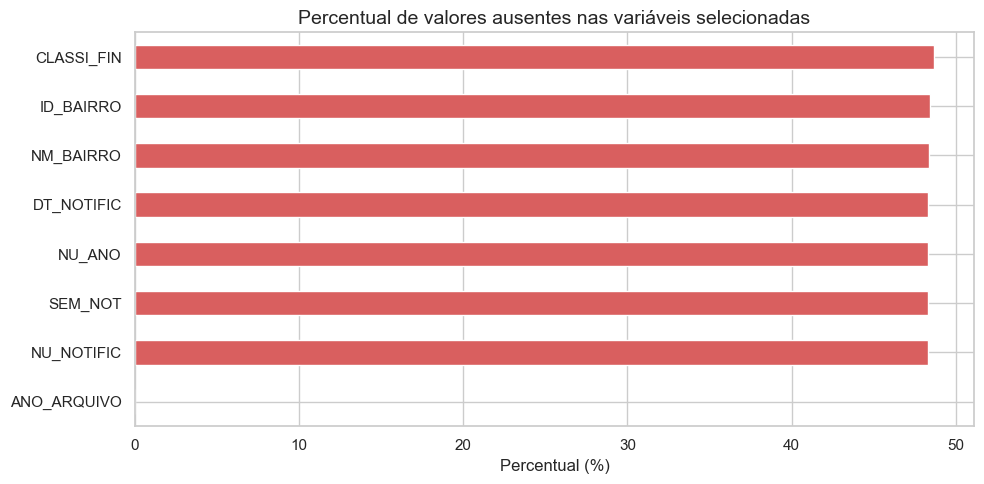

In [ ]:
ax = qualidade["percentual_ausente"].sort_values().plot.barh(
    color="#d95f5f", figsize=(10, 5)
)
ax.set_title("Percentual de valores ausentes nas variáveis selecionadas")
ax.set_xlabel("Percentual (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Limpeza e padronização

Decisões:

- converter datas e variáveis numéricas;
- remover duplicatas pelo identificador da notificação, quando disponível;
- padronizar os nomes dos bairros;
- remover registros sem ano, semana ou bairro, preservando um relatório das perdas;
- usar a semana epidemiológica da própria notificação.

In [ ]:
df = dengue.copy()

df["DT_NOTIFIC"] = pd.to_datetime(df.get("DT_NOTIFIC"), dayfirst=True, errors="coerce")
for coluna in ["SEM_NOT", "NU_ANO", "ID_BAIRRO", "CLASSI_FIN"]:
    if coluna in df:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

antes = len(df)
if "NU_NOTIFIC" in df.columns:
    df = df.drop_duplicates(subset=["NU_NOTIFIC", "ANO_ARQUIVO"])
else:
    df = df.drop_duplicates()

# O nome livre varia entre arquivos. Usamos o código territorial para recuperar
# o nome oficial do bairro no GeoJSON da Prefeitura (CBAIRRCODI // 10 = ID_BAIRRO).
recursos_area_limpeza = requests.get(
    "https://dados.recife.pe.gov.br/api/3/action/package_show?id=area-urbana",
    timeout=60,
).json()["result"]["resources"]
recurso_geo_bairros = next(
    r for r in recursos_area_limpeza
    if nome_padrao(r.get("name", "")) == "BAIRROS DO RECIFE"
    and r.get("format", "").upper() == "GEOJSON"
)
geo_bairros = requests.get(recurso_geo_bairros["url"], timeout=120).json()
mapa_id_bairro = {
    int(f["properties"]["CBAIRRCODI"]) // 10: nome_padrao(f["properties"]["EBAIRRNOME"])
    for f in geo_bairros["features"]
}

df["BAIRRO_TEXTO_ORIGINAL"] = df["NM_BAIRRO"].map(nome_padrao)
df["BAIRRO"] = df["ID_BAIRRO"].map(mapa_id_bairro)
df["BAIRRO"] = df["BAIRRO"].fillna(df["BAIRRO_TEXTO_ORIGINAL"])
df.loc[df["BAIRRO"].isin(["", "IGNORADO", "NAO INFORMADO"]), "BAIRRO"] = np.nan

# SEM_NOT costuma vir no padrão AAAASS. Se necessário, recupera ano e semana.
df["ANO"] = (df["SEM_NOT"] // 100).fillna(df["NU_ANO"])
df["SEMANA"] = (df["SEM_NOT"] % 100)

invalidas = df[
    df[["ANO", "SEMANA", "BAIRRO"]].isna().any(axis=1)
    | ~df["SEMANA"].between(1, 53)
].copy()

df_limpo = df.drop(index=invalidas.index).copy()
df_limpo["ANO"] = df_limpo["ANO"].astype(int)
df_limpo["SEMANA"] = df_limpo["SEMANA"].astype(int)

print(f"Registros antes da limpeza: {antes:,}")
print(f"Registros após a limpeza:  {len(df_limpo):,}")
print(f"Registros separados por problema de chave: {len(invalidas):,}")
display(df_limpo.head())
print("Objetivo cumprido: duplicidades, tipos, chaves inválidas e categorias foram tratados com regras explícitas.")

Registros antes da limpeza: 71,663
Registros após a limpeza:  36,869
Registros separados por problema de chave: 46


,ANO_ARQUIVO,NU_NOTIFIC,DT_NOTIFIC,SEM_NOT,NU_ANO,ID_BAIRRO,NM_BAIRRO,CLASSI_FIN,BAIRRO_TEXTO_ORIGINAL,BAIRRO,ANO,SEMANA
34601,2021,3730655,2021-01-01,202053.0,2021.0,23.0,IBURA,10.0,IBURA,IBURA,2020,53
34602,2021,3730656,2021-01-01,202053.0,2021.0,23.0,IBURA,10.0,IBURA,IBURA,2020,53
34603,2021,3730652,2021-01-01,202053.0,2021.0,23.0,IBURA,10.0,IBURA,IBURA,2020,53
34604,2021,3730657,2021-01-01,202053.0,2021.0,23.0,IBURA,10.0,IBURA,IBURA,2020,53
34605,2021,4197902,2021-01-01,202053.0,2021.0,83.0,ESTANCIA,5.0,ESTANCIA,ESTANCIA,2020,53


✅ Objetivo cumprido: duplicidades, tipos, chaves inválidas e categorias foram tratados com regras explícitas.


## 8. Agregação por bairro e semana

Cada linha da nova tabela representa um bairro em uma semana epidemiológica. Essa é a granularidade escolhida para a análise e para a futura AV2.

**Por que agregar?** A notificação individual não é a unidade da decisão pública. Para priorizar territórios, precisamos resumir as notificações por bairro e período.

In [ ]:
casos_semanais = (
    df_limpo.groupby(["ANO", "SEMANA", "BAIRRO"], as_index=False)
    .size()
    .rename(columns={"size": "CASOS_SEMANAIS"})
)

print("Dimensão bairro-semana:", casos_semanais.shape)
display(casos_semanais.head(10))
print(" Objetivo cumprido: notificações individuais foram transformadas em contagens bairro-semana.")

Dimensão bairro-semana: (11436, 4)


,ANO,SEMANA,BAIRRO,CASOS_SEMANAIS
0,2020,53,ESTANCIA,1
1,2020,53,IBURA,5
2,2020,53,LINHA DO TIRO,1
3,2021,1,AFOGADOS,1
4,2021,1,ALTO JOSE DO PINHO,1
5,2021,1,AREIAS,4
6,2021,1,BOA VIAGEM,4
7,2021,1,COELHOS,1
8,2021,1,COHAB,4
9,2021,1,COQUEIRAL,1


✅ Objetivo cumprido: notificações individuais foram transformadas em contagens bairro-semana.


## 9. População por bairro - Censo 2022/IBGE

In [ ]:
URL_POPULACAO = (
    "https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/"
    "Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/"
    "Agregados_por_bairros_basico_BR_20260520.zip"
)

conteudo_zip = baixar(URL_POPULACAO)
with zipfile.ZipFile(io.BytesIO(conteudo_zip)) as z:
    arquivo_xlsx = next(n for n in z.namelist() if n.lower().endswith(".xlsx"))
    populacao_br = pd.read_excel(io.BytesIO(z.read(arquivo_xlsx)))

pop_recife = populacao_br[
    populacao_br["NM_UF"].astype(str).map(nome_padrao).eq("PERNAMBUCO")
    & populacao_br["NM_MUN"].astype(str).map(nome_padrao).eq("RECIFE")
].copy()

pop_recife["BAIRRO"] = pop_recife["NM_BAIRRO"].map(nome_padrao)
pop_recife = pop_recife.rename(columns={
    "v0001": "POPULACAO_2022",
    "AREA_KM2": "AREA_KM2_IBGE",
})[["CD_BAIRRO", "BAIRRO", "POPULACAO_2022", "AREA_KM2_IBGE"]]

pop_recife["POPULACAO_2022"] = pd.to_numeric(pop_recife["POPULACAO_2022"], errors="coerce")
pop_recife["AREA_KM2_IBGE"] = pd.to_numeric(pop_recife["AREA_KM2_IBGE"], errors="coerce")
pop_recife["DENSIDADE_HAB_KM2"] = (
    pop_recife["POPULACAO_2022"] / pop_recife["AREA_KM2_IBGE"]
)

print("Bairros encontrados:", len(pop_recife))
print("População total:", int(pop_recife["POPULACAO_2022"].sum()))
display(pop_recife.head())
print("Objetivo cumprido: população e densidade foram obtidas para os bairros do Recife.")

Bairros encontrados: 94
População total: 1488920


,CD_BAIRRO,BAIRRO,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2
4281,2611606001,RECIFE,541,1.235592,437.846797
4282,2611606002,SANTO AMARO,27103,3.377832,8023.785433
4283,2611606003,BOA VISTA,13147,1.769746,7428.748403
4284,2611606004,SOLEDADE,2081,0.323412,6434.512984
4285,2611606005,SANTO ANTONIO,447,0.517712,863.415075


✅ Objetivo cumprido: população e densidade foram obtidas para os bairros do Recife.


## 10. RPA e geometria dos bairros - Prefeitura do Recife

In [ ]:
CKAN_AREA = (
    "https://dados.recife.pe.gov.br/api/3/action/package_show"
    "?id=area-urbana"
)

recursos_area = requests.get(CKAN_AREA, timeout=60).json()["result"]["resources"]

recurso_rpa = next(
    r for r in recursos_area
    if "bairros e rpas" in sem_acentos(r.get("name", "")).lower()
    and r.get("format", "").upper() == "CSV"
)

rpa = ler_csv_bytes(baixar(recurso_rpa["url"]))
rpa.columns = [nome_padrao(c).replace(" ", "_") for c in rpa.columns]
rpa["BAIRRO"] = rpa["BAIRRO"].map(nome_padrao)
rpa = rpa[["BAIRRO", "RPA"]].drop_duplicates()

display(rpa.head())
print(" Objetivo cumprido: os bairros receberam sua Região Político-Administrativa.")

,BAIRRO,RPA
0,AFLITOS,3
1,AFOGADOS,5
2,AGUA FRIA,2
3,ALTO DO MANDU,3
4,ALTO JOSE BONIFACIO,3


✅ Objetivo cumprido: os bairros receberam sua Região Político-Administrativa.


## 11. Integração territorial, semanas sem casos e incidência

A contagem absoluta favorece bairros populosos. Por isso criamos a incidência por 100 mil habitantes:

\[
\text{incidência} = \frac{\text{casos}}{\text{população}} \times 100.000
\]

Também construímos o painel completo de bairros e semanas. Combinações sem notificação recebem zero; sem isso, uma semana ausente poderia ser confundida com uma semana inexistente e as defasagens ficariam incorretas.

In [ ]:
bairros_casos_nao_ibge = sorted(
    set(casos_semanais["BAIRRO"].dropna()) - set(pop_recife["BAIRRO"].dropna())
)
print("Categorias de bairro das notificações sem correspondência no IBGE:", bairros_casos_nao_ibge)
registros_fora_malha = casos_semanais.loc[
    casos_semanais["BAIRRO"].isin(bairros_casos_nao_ibge), "CASOS_SEMANAIS"
].sum()
print(
    "Registros fora da malha oficial:", int(registros_fora_malha),
    f"({registros_fora_malha / casos_semanais['CASOS_SEMANAIS'].sum() * 100:.2f}% do total limpo)"
)

datas_semanais = pd.date_range("2016-01-04", "2025-12-29", freq="W-MON")
calendario = pd.DataFrame({"DATA_SEMANA": datas_semanais})
iso = calendario["DATA_SEMANA"].dt.isocalendar()
calendario["ANO"] = iso.year.astype(int)
calendario["SEMANA"] = iso.week.astype(int)
calendario = calendario[calendario["ANO"].between(2016, 2025)]

grade = (
    pop_recife[["BAIRRO"]].drop_duplicates().assign(chave=1)
    .merge(calendario[["ANO", "SEMANA", "DATA_SEMANA"]].assign(chave=1), on="chave")
    .drop(columns="chave")
)

base = (
    grade.merge(casos_semanais, on=["ANO", "SEMANA", "BAIRRO"], how="left")
    .merge(pop_recife, on="BAIRRO", how="left")
    .merge(rpa, on="BAIRRO", how="left")
)
base["CASOS_SEMANAIS"] = base["CASOS_SEMANAIS"].fillna(0).astype(int)

base["INCIDENCIA_100MIL"] = (
    base["CASOS_SEMANAIS"] / base["POPULACAO_2022"] * 100_000
)

nao_casados = sorted(base.loc[base["POPULACAO_2022"].isna(), "BAIRRO"].unique())
print("Bairros sem correspondência populacional:", nao_casados)
print("Percentual com população:", round(base["POPULACAO_2022"].notna().mean() * 100, 2), "%")
display(base.head())
print("Semanas no painel:", base[["ANO", "SEMANA"]].drop_duplicates().shape[0])
print("Objetivo cumprido: painel territorial completo criado, incluindo semanas com zero casos.")

Categorias de bairro das notificações sem correspondência no IBGE: ['ALTO DA BONDADE', "ALTO JOS' DO PINHO", 'ALTO JOS\x90 DO PINHO', 'BREJ', "CAIXA D' ΜGUA", 'COQUEIRO SECO', 'CORREGO JENIPAPO', 'FUNDÆO', 'GUAB', 'GUABIR', 'HIPADROMO', 'JAGUARANA', 'JARDIM ATLANTICO', 'JIQU]', 'MIRUEIRA', 'RESIDENCIAL', 'SITIO DOS PINTOS', 'TEJUCOPAPO', 'VASC', 'VASCO']
Registros fora da malha oficial: 213 (0.58% do total limpo)
Bairros sem correspondência populacional: []
Percentual com população: 100.0 %


,BAIRRO,ANO,SEMANA,DATA_SEMANA,CASOS_SEMANAIS,CD_BAIRRO,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,INCIDENCIA_100MIL
0,RECIFE,2016,1,2016-01-04,0,2611606001,541,1.235592,437.846797,1,0.0
1,RECIFE,2016,2,2016-01-11,0,2611606001,541,1.235592,437.846797,1,0.0
2,RECIFE,2016,3,2016-01-18,0,2611606001,541,1.235592,437.846797,1,0.0
3,RECIFE,2016,4,2016-01-25,0,2611606001,541,1.235592,437.846797,1,0.0
4,RECIFE,2016,5,2016-02-01,0,2611606001,541,1.235592,437.846797,1,0.0


Semanas no painel: 521
✅ Objetivo cumprido: painel territorial completo criado, incluindo semanas com zero casos.


## 12. Dados climáticos do INMET

Os ZIPs anuais do INMET contêm todas as estações automáticas do Brasil. A célula abaixo baixa cada ano, seleciona somente a estação **A301 - Recife** e resume as observações horárias por semana.

> Esta célula pode levar alguns minutos porque os arquivos anuais são grandes. Os dados automáticos são brutos e podem apresentar `9999`, valores nulos ou falhas de sensores; essas ocorrências serão tratadas como ausentes.

In [ ]:
def escolher_coluna(colunas, termos):
    normalizadas = {c: nome_padrao(c) for c in colunas}
    for original, normalizada in normalizadas.items():
        if all(t in normalizada for t in termos):
            return original
    return None


def carregar_inmet_recife(anos=range(2016, 2026), estacao="A301"):
    partes = []

    for ano in anos:
        url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
        print(f"INMET {ano}...", end=" ")
        conteudo = baixar(url, timeout=600)

        with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
            membros = [
                n for n in z.namelist()
                if estacao in nome_padrao(n) and n.lower().endswith(".csv")
            ]
            if not membros:
                print("estação não encontrada")
                continue

            dados = pd.read_csv(
                io.BytesIO(z.read(membros[0])),
                sep=";",
                skiprows=8,
                encoding="latin-1",
                decimal=",",
                low_memory=False,
            )

        dados.columns = [c.strip() for c in dados.columns]
        col_data = escolher_coluna(dados.columns, ["DATA"])
        col_chuva = escolher_coluna(dados.columns, ["PRECIPITACAO", "TOTAL"])
        col_temp = escolher_coluna(dados.columns, ["TEMPERATURA DO AR", "BULBO SECO"])
        col_umid = escolher_coluna(dados.columns, ["UMIDADE RELATIVA DO AR", "HORARIA"])

        selecionadas = [c for c in [col_data, col_chuva, col_temp, col_umid] if c]
        dados = dados[selecionadas].copy()
        dados = dados.rename(columns={
            col_data: "DATA",
            col_chuva: "PRECIPITACAO_MM",
            col_temp: "TEMPERATURA_C",
            col_umid: "UMIDADE_PCT",
        })

        dados["DATA"] = pd.to_datetime(dados["DATA"], errors="coerce")
        for c in ["PRECIPITACAO_MM", "TEMPERATURA_C", "UMIDADE_PCT"]:
            if c in dados:
                dados[c] = pd.to_numeric(dados[c], errors="coerce")
                dados.loc[dados[c].abs() >= 9999, c] = np.nan

        partes.append(dados)
        print(f"{len(dados):,} observações")

    if not partes:
        raise RuntimeError("A estação A301 não foi encontrada nos anos solicitados.")
    return pd.concat(partes, ignore_index=True)

### 12.1 Download dos anos e seleção da estação

Esta célula é separada porque concentra a etapa mais demorada. O log mostra claramente quais anos possuem a estação A301 no arquivo anual. Ausência de uma estação em determinado ano é mantida como limitação, nunca inventada ou imputada sem justificativa.

In [ ]:
clima_horario = carregar_inmet_recife()
display(clima_horario.head())
print("✅ Objetivo cumprido: observações horárias da estação A301 foram obtidas sem upload manual.")

INMET 2016... 

8,784 observações
INMET 2017... 

8,760 observações
INMET 2018... 

8,760 observações
INMET 2019... 

8,760 observações
INMET 2020... 

8,784 observações
INMET 2021... 

... (3 outputs left out)

estação não encontrada
INMET 2025... 

estação não encontrada


,DATA,PRECIPITACAO_MM,TEMPERATURA_C,UMIDADE_PCT
0,2016-01-01,0.0,25.7,70.0
1,2016-01-01,0.0,25.2,75.0
2,2016-01-01,0.0,25.0,78.0
3,2016-01-01,0.0,25.0,78.0
4,2016-01-01,0.0,24.3,78.0


✅ Objetivo cumprido: observações horárias da estação A301 foram obtidas sem upload manual.


In [ ]:
clima_diario = (
    clima_horario.dropna(subset=["DATA"])
    .groupby("DATA", as_index=False)
    .agg(
        PRECIPITACAO_MM=("PRECIPITACAO_MM", "sum"),
        TEMPERATURA_MEDIA_C=("TEMPERATURA_C", "mean"),
        UMIDADE_MEDIA_PCT=("UMIDADE_PCT", "mean"),
    )
)

iso = clima_diario["DATA"].dt.isocalendar()
clima_diario["ANO"] = iso.year.astype(int)
clima_diario["SEMANA"] = iso.week.astype(int)

clima_semanal = (
    clima_diario.groupby(["ANO", "SEMANA"], as_index=False)
    .agg(
        PRECIPITACAO_SEMANAL_MM=("PRECIPITACAO_MM", "sum"),
        TEMPERATURA_MEDIA_C=("TEMPERATURA_MEDIA_C", "mean"),
        UMIDADE_MEDIA_PCT=("UMIDADE_MEDIA_PCT", "mean"),
    )
)

base = base.merge(clima_semanal, on=["ANO", "SEMANA"], how="left")
display(base.head())
print("Objetivo cumprido: clima horário foi tratado e agregado na mesma granularidade bairro-semana.")

,BAIRRO,ANO,SEMANA,DATA_SEMANA,CASOS_SEMANAIS,CD_BAIRRO,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,INCIDENCIA_100MIL,PRECIPITACAO_SEMANAL_MM,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT
0,RECIFE,2016,1,2016-01-04,0,2611606001,541,1.235592,437.846797,1,0.0,32.0,27.037500,73.896645
1,RECIFE,2016,2,2016-01-11,0,2611606001,541,1.235592,437.846797,1,0.0,13.0,27.256548,74.398810
2,RECIFE,2016,3,2016-01-18,0,2611606001,541,1.235592,437.846797,1,0.0,57.0,26.701190,76.500000
3,RECIFE,2016,4,2016-01-25,0,2611606001,541,1.235592,437.846797,1,0.0,15.2,26.689984,70.681677
4,RECIFE,2016,5,2016-02-01,0,2611606001,541,1.235592,437.846797,1,0.0,7.4,28.332390,63.135008


✅ Objetivo cumprido: clima horário foi tratado e agregado na mesma granularidade bairro-semana.


## 13. Feature engineering

Criamos variáveis que representam sazonalidade, condições recentes e tendência temporal. Todas as defasagens usam apenas semanas anteriores, evitando usar informação futura.

Conforme a aula, aplicamos quatro tipos:

| Tipo | Aplicação no projeto |
|---|---|
| Transformação | mês, trimestre e período chuvoso a partir da data |
| Criação | defasagens de 1 a 4 semanas |
| Combinação | incidência por 100 mil habitantes |
| Agregação | média móvel de casos e chuva acumulada em 4 semanas |

Uma boa feature precisa ter utilidade, sentido no contexto de saúde e estar disponível no momento da previsão. Por isso, nenhuma feature usa casos futuros.

In [ ]:
base = base.sort_values(["BAIRRO", "ANO", "SEMANA"]).reset_index(drop=True)

# Data aproximada a partir do calendário ISO.
base["DATA_SEMANA"] = pd.to_datetime(
    base["ANO"].astype(str) + "-W" + base["SEMANA"].astype(str).str.zfill(2) + "-1",
    format="%G-W%V-%u",
    errors="coerce",
)

base["MES"] = base["DATA_SEMANA"].dt.month
base["TRIMESTRE"] = base["DATA_SEMANA"].dt.quarter
base["PERIODO_CHUVOSO"] = base["MES"].between(3, 8).astype("Int64")

for atraso in (1, 2, 3, 4):
    base[f"CASOS_LAG_{atraso}"] = base.groupby("BAIRRO")["CASOS_SEMANAIS"].shift(atraso)

base["MEDIA_CASOS_4S"] = (
    base.groupby("BAIRRO")["CASOS_SEMANAIS"]
    .transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
)

# Target candidato para a AV2. Ele é guardado como alvo, nunca como feature.
base["CASOS_PROXIMA_SEMANA"] = base.groupby("BAIRRO")["CASOS_SEMANAIS"].shift(-1)

chuva_4s = clima_semanal.sort_values(["ANO", "SEMANA"])[
    ["ANO", "SEMANA", "PRECIPITACAO_SEMANAL_MM"]
].copy()
chuva_4s["CHUVA_4S_MM"] = chuva_4s["PRECIPITACAO_SEMANAL_MM"].rolling(
    4, min_periods=1
).sum()
base = base.merge(
    chuva_4s[["ANO", "SEMANA", "CHUVA_4S_MM"]],
    on=["ANO", "SEMANA"],
    how="left",
)

features_criadas = [
    "MES", "TRIMESTRE", "PERIODO_CHUVOSO", "INCIDENCIA_100MIL",
    "CASOS_LAG_1", "CASOS_LAG_2", "CASOS_LAG_3", "CASOS_LAG_4",
    "MEDIA_CASOS_4S", "CHUVA_4S_MM", "DENSIDADE_HAB_KM2", "RPA"
]
display(base[features_criadas].describe(include="all").T)
print("✅ Objetivo cumprido: features úteis foram criadas sem usar informação futura.")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
MES,48974.0,NaN,NaN,NaN,6.50096,3.444202,1.0,4.0,7.0,9.0,12.0
TRIMESTRE,48974.0,NaN,NaN,NaN,2.504798,1.115457,1.0,2.0,3.0,3.0,4.0
PERIODO_CHUVOSO,48974.0,<NA>,<NA>,<NA>,0.502879,0.499997,0.0,0.0,1.0,1.0,1.0
INCIDENCIA_100MIL,48974.0,NaN,NaN,NaN,5.162943,21.8702,0.0,0.0,0.0,0.0,1112.744069
CASOS_LAG_1,48880.0,NaN,NaN,NaN,0.7482,2.538594,0.0,0.0,0.0,0.0,83.0
CASOS_LAG_2,48786.0,NaN,NaN,NaN,0.747243,2.539455,0.0,0.0,0.0,0.0,83.0
CASOS_LAG_3,48692.0,NaN,NaN,NaN,0.746283,2.540553,0.0,0.0,0.0,0.0,83.0
CASOS_LAG_4,48598.0,NaN,NaN,NaN,0.744516,2.540241,0.0,0.0,0.0,0.0,83.0
MEDIA_CASOS_4S,48880.0,NaN,NaN,NaN,0.74441,2.27589,0.0,0.0,0.0,0.5,66.0
CHUVA_4S_MM,39198.0,NaN,NaN,NaN,105.889688,124.547014,0.0,0.0,63.0,169.8,499.8


✅ Objetivo cumprido: features úteis foram criadas sem usar informação futura.


## 14. Análise exploratória orientada por perguntas

A EDA não é uma coleção aleatória de gráficos. Cada visualização abaixo segue o fluxo **pergunta → evidência → interpretação → insight** apresentado em aula.

### 14.1 Pergunta: como se distribuem os casos semanais?

O histograma mostra a forma da distribuição; o boxplot destaca mediana, quartis e possíveis valores extremos. Picos de casos não são removidos automaticamente: podem representar surtos reais, e não erros.

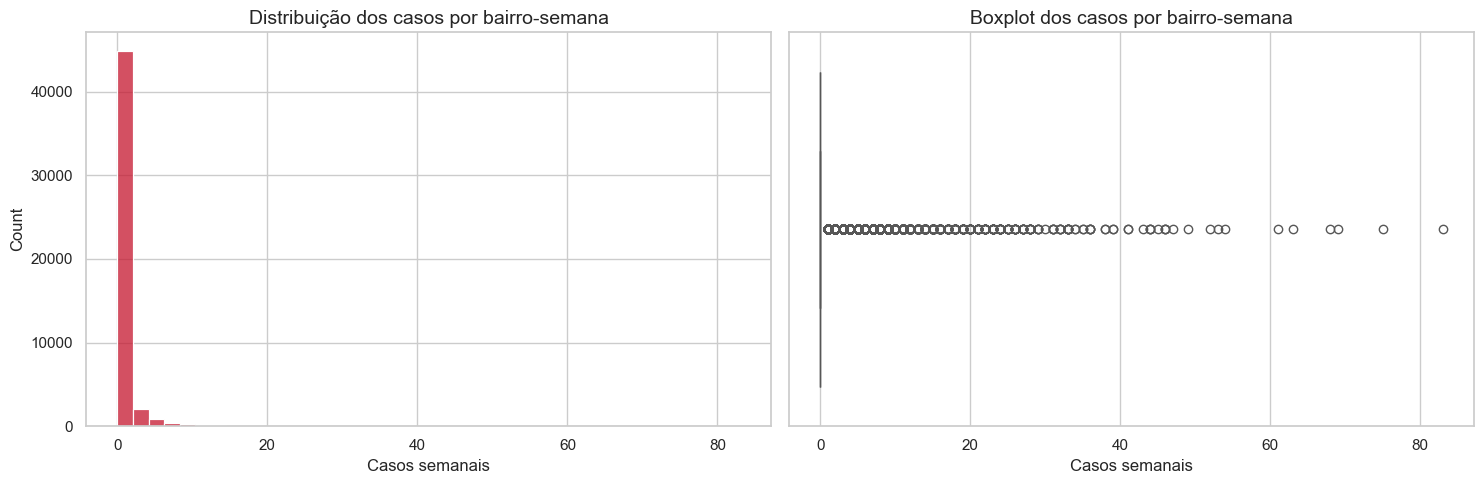

Limite superior pelo IQR: 0.00
Pontos sinalizados para investigação: 11,312
Decisão: manter esses pontos, pois picos epidemiológicos podem ser eventos reais.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(base["CASOS_SEMANAIS"], bins=40, ax=axes[0], color="#c5162e")
axes[0].set_title("Distribuição dos casos por bairro-semana")
axes[0].set_xlabel("Casos semanais")

sns.boxplot(x=base["CASOS_SEMANAIS"], ax=axes[1], color="#e58f3c")
axes[1].set_title("Boxplot dos casos por bairro-semana")
axes[1].set_xlabel("Casos semanais")
plt.tight_layout()
plt.show()

q1, q3 = base["CASOS_SEMANAIS"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
potenciais_outliers = base[base["CASOS_SEMANAIS"] > limite_superior]
print(f"Limite superior pelo IQR: {limite_superior:.2f}")
print(f"Pontos sinalizados para investigação: {len(potenciais_outliers):,}")
print("Decisão: manter esses pontos, pois picos epidemiológicos podem ser eventos reais.")

### 14.2 Pergunta: em quais anos e meses os registros se concentram?

Gráfico de barras compara anos; linha mensal evidencia sazonalidade. O resultado ajuda a contar quando a pressão epidemiológica costuma aumentar.

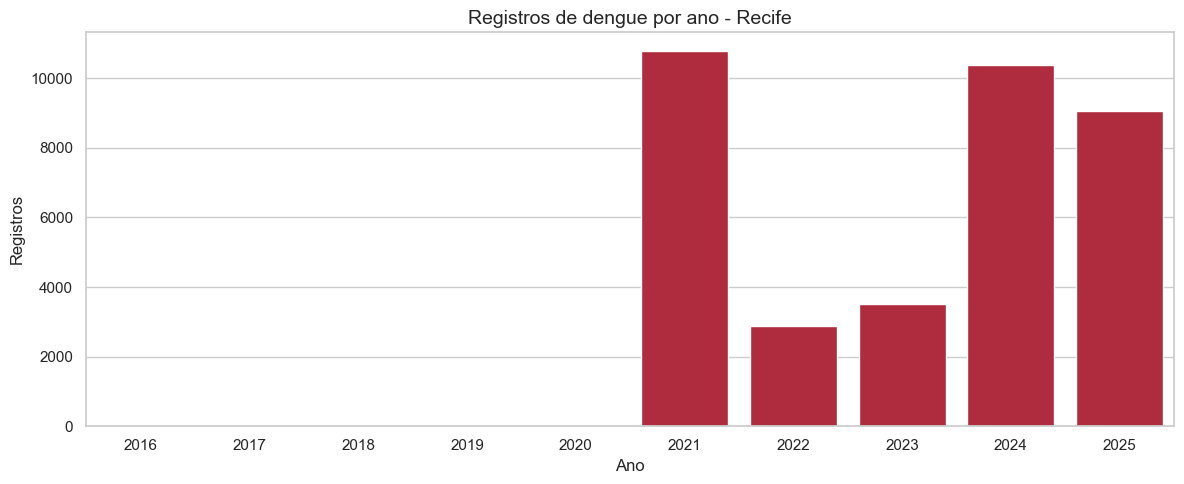

In [ ]:
casos_ano = base.groupby("ANO", as_index=False)["CASOS_SEMANAIS"].sum()
sns.barplot(data=casos_ano, x="ANO", y="CASOS_SEMANAIS", color="#c5162e")
plt.title("Registros de dengue por ano - Recife")
plt.xlabel("Ano")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

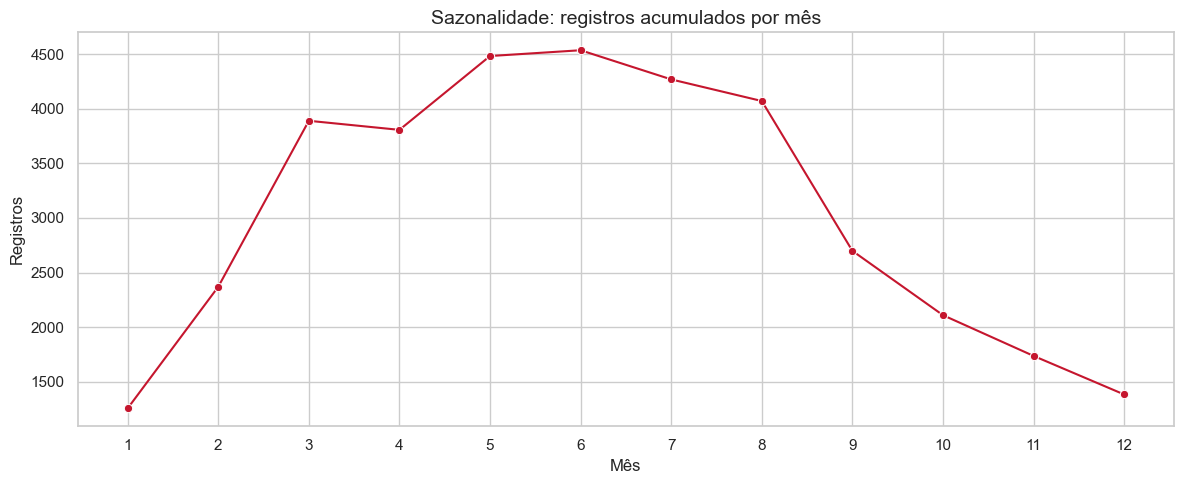

In [ ]:
casos_mes = base.groupby("MES", as_index=False)["CASOS_SEMANAIS"].sum()
sns.lineplot(data=casos_mes, x="MES", y="CASOS_SEMANAIS", marker="o", color="#c5162e")
plt.title("Sazonalidade: registros acumulados por mês")
plt.xticks(range(1, 13))
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

### 14.3 Pergunta: onde está a maior carga territorial?

O total absoluto indica volume de demanda. A incidência corrige pela população e permite uma comparação mais justa entre bairros de tamanhos diferentes. As duas medidas respondem a perguntas complementares.

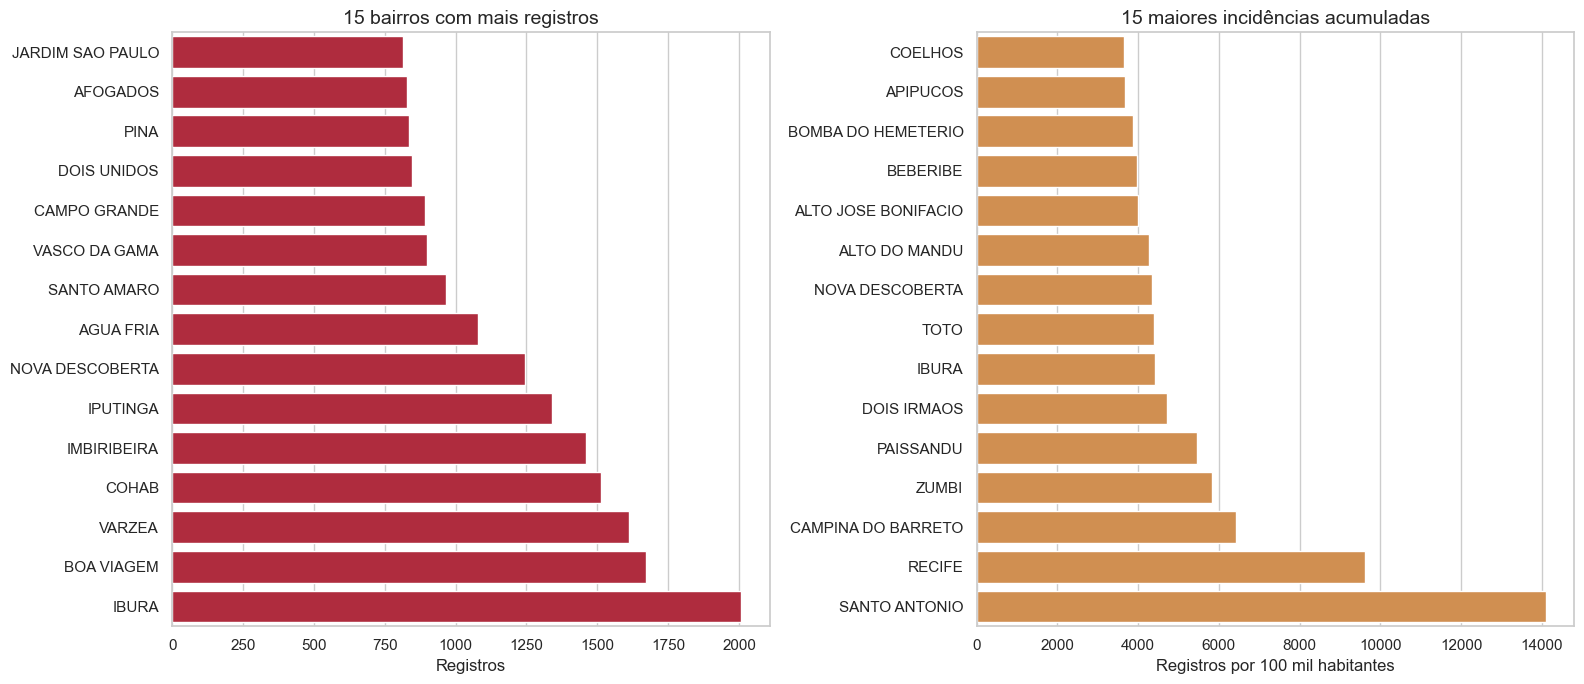

In [ ]:
ranking = (
    base.groupby("BAIRRO", as_index=False)
    .agg(
        CASOS=("CASOS_SEMANAIS", "sum"),
        POPULACAO=("POPULACAO_2022", "first"),
    )
)
ranking["INCIDENCIA_ACUM_100MIL"] = ranking["CASOS"] / ranking["POPULACAO"] * 100_000

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_casos = ranking.nlargest(15, "CASOS").sort_values("CASOS")
sns.barplot(data=top_casos, y="BAIRRO", x="CASOS", ax=axes[0], color="#c5162e")
axes[0].set_title("15 bairros com mais registros")
axes[0].set_xlabel("Registros")
axes[0].set_ylabel("")

top_inc = ranking.replace([np.inf, -np.inf], np.nan).dropna().nlargest(15, "INCIDENCIA_ACUM_100MIL").sort_values("INCIDENCIA_ACUM_100MIL")
sns.barplot(data=top_inc, y="BAIRRO", x="INCIDENCIA_ACUM_100MIL", ax=axes[1], color="#e58f3c")
axes[1].set_title("15 maiores incidências acumuladas")
axes[1].set_xlabel("Registros por 100 mil habitantes")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 14.4 Pergunta: chuva, temperatura e umidade se relacionam com os casos?

O scatter plot mostra a forma da relação chuva-casos. O heatmap resume a força das relações lineares. Valores próximos de zero significam pouca relação **linear contemporânea**, não ausência de qualquer relação.

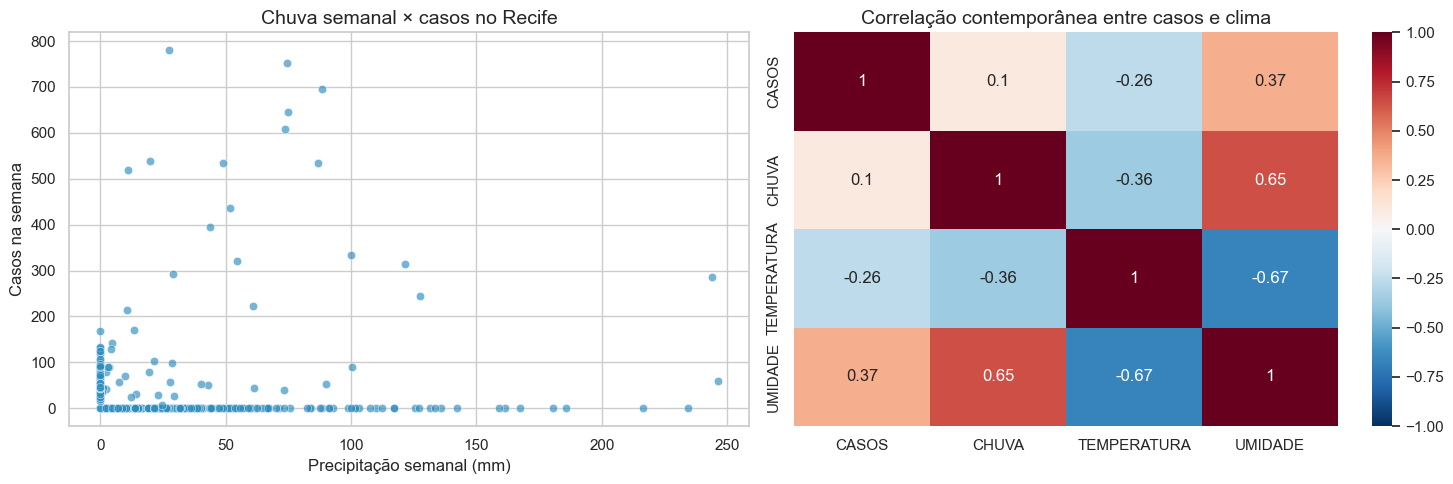

In [ ]:
serie_recife = (
    base.groupby(["ANO", "SEMANA"], as_index=False)
    .agg(
        CASOS=("CASOS_SEMANAIS", "sum"),
        CHUVA=("PRECIPITACAO_SEMANAL_MM", "first"),
        TEMPERATURA=("TEMPERATURA_MEDIA_C", "first"),
        UMIDADE=("UMIDADE_MEDIA_PCT", "first"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=serie_recife, x="CHUVA", y="CASOS", alpha=0.65, ax=axes[0], color="#2b8cbe")
axes[0].set_title("Chuva semanal × casos no Recife")
axes[0].set_xlabel("Precipitação semanal (mm)")
axes[0].set_ylabel("Casos na semana")

correlacoes = serie_recife[["CASOS", "CHUVA", "TEMPERATURA", "UMIDADE"]].corr()
sns.heatmap(correlacoes, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlação contemporânea entre casos e clima")
plt.tight_layout()
plt.show()

### Defasagens entre clima e casos

Esta análise verifica se o clima de uma semana apresenta associação com os casos registrados de uma a quatro semanas depois. Correlação não prova causalidade, mas ajuda a identificar defasagens úteis para a AV2.

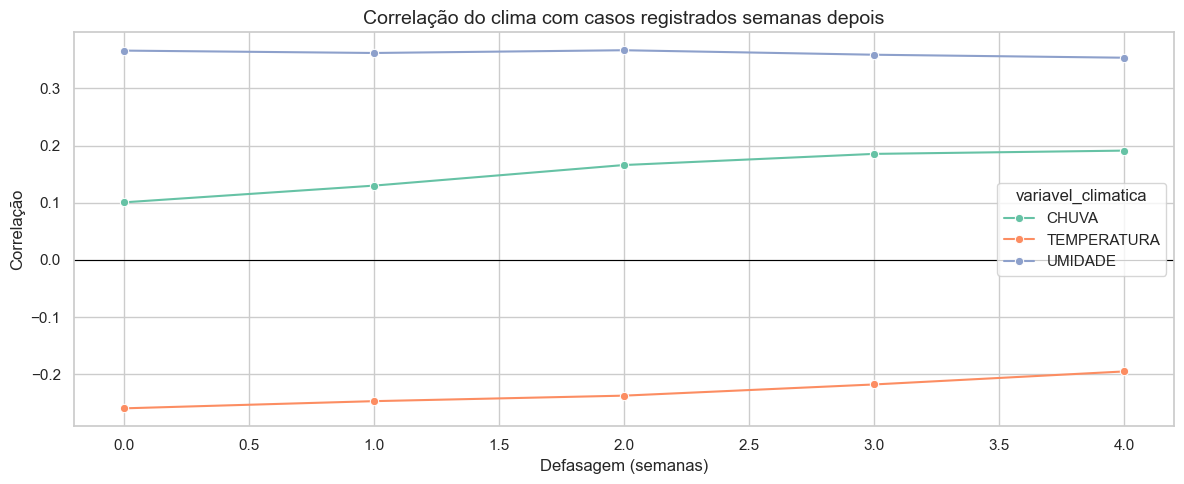

,variavel_climatica,casos_semanas_depois,correlacao
12,UMIDADE,2,0.366609
10,UMIDADE,0,0.365969
11,UMIDADE,1,0.361819
13,UMIDADE,3,0.358766
14,UMIDADE,4,0.353538
4,CHUVA,4,0.191134
3,CHUVA,3,0.185411
2,CHUVA,2,0.165925
1,CHUVA,1,0.129926
0,CHUVA,0,0.100700


✅ Objetivo cumprido: distribuições, extremos, categorias e relações foram investigados com visualizações adequadas.


In [ ]:
serie_recife = serie_recife.sort_values(["ANO", "SEMANA"]).reset_index(drop=True)

linhas = []
for variavel in ["CHUVA", "TEMPERATURA", "UMIDADE"]:
    for atraso in range(0, 5):
        correlacao = serie_recife[variavel].corr(serie_recife["CASOS"].shift(-atraso))
        linhas.append({
            "variavel_climatica": variavel,
            "casos_semanas_depois": atraso,
            "correlacao": correlacao,
        })

corr_lags = pd.DataFrame(linhas)
sns.lineplot(
    data=corr_lags,
    x="casos_semanas_depois",
    y="correlacao",
    hue="variavel_climatica",
    marker="o",
)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlação do clima com casos registrados semanas depois")
plt.xlabel("Defasagem (semanas)")
plt.ylabel("Correlação")
plt.tight_layout()
plt.show()

display(corr_lags.sort_values("correlacao", ascending=False))
print("✅ Objetivo cumprido: distribuições, extremos, categorias e relações foram investigados com visualizações adequadas.")

## 15. Principais descobertas

Esta célula transforma os resultados em uma narrativa automática, evitando encerrar a EDA apenas com gráficos.

In [ ]:
ano_pico = casos_ano.loc[casos_ano["CASOS_SEMANAIS"].idxmax()]
mes_pico = casos_mes.loc[casos_mes["CASOS_SEMANAIS"].idxmax()]
bairro_casos = ranking.loc[ranking["CASOS"].idxmax()]
bairro_inc = ranking.dropna(subset=["INCIDENCIA_ACUM_100MIL"]).loc[
    ranking.dropna(subset=["INCIDENCIA_ACUM_100MIL"])["INCIDENCIA_ACUM_100MIL"].idxmax()
]
melhor_lag = corr_lags.dropna().loc[corr_lags["correlacao"].abs().idxmax()]

print("STORYTELLING DOS RESULTADOS")
print("=" * 60)
print(f"• O maior volume anual ocorreu em {int(ano_pico['ANO'])}, com {int(ano_pico['CASOS_SEMANAIS']):,} registros.")
print(f"• Considerando todos os anos, o mês {int(mes_pico['MES'])} concentrou o maior volume.")
print(f"• {bairro_casos['BAIRRO']} liderou em volume absoluto ({int(bairro_casos['CASOS']):,} registros).")
print(f"• {bairro_inc['BAIRRO']} apresentou a maior incidência acumulada ({bairro_inc['INCIDENCIA_ACUM_100MIL']:.1f}/100 mil).")
print(
    f"• A associação linear de maior magnitude foi {melhor_lag['variavel_climatica']} "
    f"com casos {int(melhor_lag['casos_semanas_depois'])} semana(s) depois "
    f"(r={melhor_lag['correlacao']:.3f})."
)
print("• Correlação é evidência de associação, não prova causalidade.")
print("\n✅ Objetivo cumprido: gráficos foram convertidos em evidências interpretáveis para a decisão pública.")

STORYTELLING DOS RESULTADOS
• O maior volume anual ocorreu em 2021, com 10,782 registros.
• Considerando todos os anos, o mês 6 concentrou o maior volume.
• IBURA liderou em volume absoluto (2,007 registros).
• SANTO ANTONIO apresentou a maior incidência acumulada (14094.0/100 mil).
• A associação linear de maior magnitude foi UMIDADE com casos 2 semana(s) depois (r=0.367).
• Correlação é evidência de associação, não prova causalidade.

✅ Objetivo cumprido: gráficos foram convertidos em evidências interpretáveis para a decisão pública.


### Limitações que acompanham os resultados

- notificações podem sofrer subnotificação e atraso;
- a população do Censo 2022 é usada como referência para todo o período;
- uma única estação do INMET representa o clima municipal e não captura microclimas de todos os bairros;
- dados IoT hiperlocais ainda não estão disponíveis e serão a hipótese de enriquecimento futuro;
- correlação não estabelece causalidade;
- a classificação final dos registros deve ser revisitada conforme a definição epidemiológica adotada pela equipe.

**Conclusão da AV1:** os dados foram adquiridos, compreendidos, limpos, integrados e transformados; padrões temporais e territoriais foram investigados; e a base ficou pronta para a etapa de modelagem.

## 16. Exportação da base tratada

In [ ]:
colunas_finais = [
    "ANO", "SEMANA", "DATA_SEMANA", "BAIRRO", "RPA",
    "CASOS_SEMANAIS", "POPULACAO_2022", "AREA_KM2_IBGE",
    "DENSIDADE_HAB_KM2", "INCIDENCIA_100MIL",
    "PRECIPITACAO_SEMANAL_MM", "TEMPERATURA_MEDIA_C", "UMIDADE_MEDIA_PCT",
    "MES", "TRIMESTRE", "PERIODO_CHUVOSO", "CHUVA_4S_MM",
    "CASOS_LAG_1", "CASOS_LAG_2", "CASOS_LAG_3", "CASOS_LAG_4",
    "MEDIA_CASOS_4S", "CASOS_PROXIMA_SEMANA",
]

base_final = base[[c for c in colunas_finais if c in base.columns]].copy()
caminho_saida = DATA_DIR.parent / "dataset_av1_dengue_recife_tratado.csv"
base_final.to_csv(caminho_saida, index=False, encoding="utf-8-sig")

print("Arquivo salvo em:", caminho_saida)
print("Dimensão final:", base_final.shape)
display(base_final.head())
print("✅ Objetivo cumprido: base tratada e documentada foi exportada para uso posterior.")

Arquivo salvo em: dataset_av1_dengue_recife_tratado.csv
Dimensão final: (48974, 23)


,ANO,SEMANA,DATA_SEMANA,BAIRRO,RPA,CASOS_SEMANAIS,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,INCIDENCIA_100MIL,PRECIPITACAO_SEMANAL_MM,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT,MES,TRIMESTRE,PERIODO_CHUVOSO,CHUVA_4S_MM,CASOS_LAG_1,CASOS_LAG_2,CASOS_LAG_3,CASOS_LAG_4,MEDIA_CASOS_4S,CASOS_PROXIMA_SEMANA
0,2016,1,2016-01-04,AFLITOS,3,0,4990,0.306695,16270.235902,0.0,32.0,27.037500,73.896645,1,1,0,32.0,NaN,NaN,NaN,NaN,NaN,0.0
1,2016,2,2016-01-11,AFLITOS,3,0,4990,0.306695,16270.235902,0.0,13.0,27.256548,74.398810,1,1,0,45.0,0.0,NaN,NaN,NaN,0.0,0.0
2,2016,3,2016-01-18,AFLITOS,3,0,4990,0.306695,16270.235902,0.0,57.0,26.701190,76.500000,1,1,0,102.0,0.0,0.0,NaN,NaN,0.0,0.0
3,2016,4,2016-01-25,AFLITOS,3,0,4990,0.306695,16270.235902,0.0,15.2,26.689984,70.681677,1,1,0,117.2,0.0,0.0,0.0,NaN,0.0,0.0
4,2016,5,2016-02-01,AFLITOS,3,0,4990,0.306695,16270.235902,0.0,7.4,28.332390,63.135008,2,1,0,92.6,0.0,0.0,0.0,0.0,0.0,0.0


✅ Objetivo cumprido: base tratada e documentada foi exportada para uso posterior.


### 16.1 Download opcional

No Colab, execute a célula abaixo somente quando quiser salvar uma cópia local do CSV. Fora do Colab, ela apenas informa onde o arquivo foi gravado.

In [ ]:
try:
    from google.colab import files
    files.download(str(caminho_saida))
except ImportError:
    print("Fora do Colab. Arquivo disponível em:", caminho_saida)

Fora do Colab. Arquivo disponível em: dataset_av1_dengue_recife_tratado.csv
